# STPath Small–Flash: Hist2ST 

This model predicts gene expression from a spatial window of patches. The example is patch 0 of held-out slide `23270_D2`. The default call uses saved GigaPath-Flash embeddings in `stpath_flash_window.npz`. To extract embeddings from the original patches instead, use the `source="images"` call shown at the end. That path downloads the GigaPath-Flash tile weights if needed.

In [10]:
from pathlib import Path
import hashlib
import json
import sys
import warnings
warnings.filterwarnings("ignore", message="IProgress not found.*")
warnings.filterwarnings("ignore", message="Importing from timm.models.* is deprecated")
warnings.filterwarnings("ignore", message="An issue occurred while importing 'torch-cluster'.*")

import numpy as np
import pandas as pd
import torch
from PIL import Image
from torchvision import transforms
from scipy.stats import pearsonr, spearmanr
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "code_model_training/models/models.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from the TinyHistModels folder.")
sys.path.insert(0, str(ROOT / "code_model_training/models"))
sys.path.insert(0, str(ROOT / "code_model_training"))
from models import STPathSmallFlashScratchModel
from utils.dataPrep import SpatialPatchDataset

DEMO = ROOT / "demo"
metadata = json.loads((DEMO / "sample/stpath_flash_metadata.json").read_text())
genes = np.load(ROOT / "code_model_training/gene_outputs/hist2st_845.npy",
                allow_pickle=True).astype(str)
assert len(genes) == metadata["num_genes"] == 845
torch.set_num_threads(4)


## Run the model

`run_demo()` loads the saved embeddings and spatial coordinates. `run_demo(source="images")` reads the prepared slide, downloads Flash weights from Hugging Face if absent, extracts embeddings, then calls the same spatial model. The checkpoint contains the trained image projection, mask and metadata embeddings, spatial transformer and regression head.

In [11]:
def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def flash_weights(assets_dir):
    path = assets_dir / "gigapath_flash/pytorch_model.bin"
    if not path.is_file():
        from huggingface_hub import hf_hub_download
        print("Downloading GigaPath-Flash tile weights...")
        hf_hub_download(repo_id="prov-gigapath/prov-gigapath-flash",
                        filename="pytorch_model.bin", local_dir=path.parent)
    if sha256(path) != metadata["flash_encoder_sha256"]:
        raise ValueError("Flash weights differ from those used for this run.")
    return path


def run_demo(source="cached", data_dir=None, assets_dir=None):
    checkpoint = DEMO / metadata["head_checkpoint"]
    assert sha256(checkpoint) == metadata["head_checkpoint_sha256"]
    if source == "cached":
        window_path = DEMO / metadata["window_features"]
        assert sha256(window_path) == metadata["window_features_sha256"]
        with np.load(window_path, allow_pickle=False) as window:
            features = torch.from_numpy(window["features"].copy())
            coords = torch.from_numpy(window["coords"].copy())
            spot_ids = window["spot_ids"].astype(str)
        flash_ckpt = None
    elif source == "images":
        data_dir = Path(data_dir or ROOT / "data/hist2st")
        assets_dir = Path(assets_dir or ROOT / "assets")
        slide = metadata["sample_id"]
        h5, h5ad = data_dir / f"{slide}.h5", data_dir / f"{slide}.h5ad"
        if not h5.is_file() or not h5ad.is_file():
            raise FileNotFoundError(f"Download and prepare {h5.name} and {h5ad.name} in {data_dir}.")
        flash_weights(assets_dir)  # Uses your Hugging Face login for the gated model.
        flash_ckpt = "pytorch_model.bin"
        transform = transforms.Compose([
            transforms.ToPILImage(), transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
        ])
        window = SpatialPatchDataset(h5ad, h5, gene_names=genes, transform=transform,
                                     log_norm=True, scale_factor=metadata["scale_factor"],
                                     window_size=metadata["window_size"],
                                     window_stride=metadata["window_stride"])
        images, coords, _ = window[0]
        spot_ids = np.asarray([window.spot_ids[int(i)] for i in window.window_indices[0]])
    else:
        raise ValueError("source must be 'cached' or 'images'")
    assert len(spot_ids) == metadata["window_size"]
    assert spot_ids[0] == metadata["spot_id"]
    model = STPathSmallFlashScratchModel(
        panel_gene_names=genes, assets_dir=str(assets_dir or ROOT / "assets"),
        gigapath_flash_ckpt=flash_ckpt,
        organ_type=metadata["organ_type"], tech_type=metadata["tech_type"],
    )
    state = torch.load(checkpoint, map_location="cpu", weights_only=True)
    if flash_ckpt is None:
        model.load_state_dict(state, strict=True)
    else:
        missing, unexpected = model.load_state_dict(state, strict=False)
        assert missing and all(key.startswith("gigapath_backbone.") for key in missing)
        assert not unexpected
    model.eval()
    with torch.inference_mode():
        if flash_ckpt is not None:
            features = torch.cat([
                model.gigapath_backbone(images[i:i + 16])
                for i in range(0, len(images), 16)
            ])
            print(f"Extracted Flash embeddings for {len(features)} patches.")
        predictions = model(img_features=features, coords=coords,
                            batch_idx=torch.zeros(len(features), dtype=torch.long)).numpy()
    assert predictions.shape == (len(spot_ids), len(genes))
    prediction = predictions[metadata["window_target_position"]]
    expression_path = DEMO / metadata["expression"]
    assert sha256(expression_path) == metadata["expression_sha256"]
    expression = pd.read_csv(expression_path).set_index("gene")
    counts = expression.loc[genes, "count"].to_numpy(dtype=np.float32)
    target = np.log1p(counts / (counts.sum() + np.float32(1e-8)) * metadata["scale_factor"])
    error = prediction - target
    nonzero = np.abs(target) > 1e-3
    metrics = pd.Series({
        "Pearson (patch-wise)": float(pearsonr(target, prediction).statistic),
        "Spearman (patch-wise)": float(spearmanr(target, prediction).statistic),
        "MAE": float(np.mean(np.abs(error))),
        "MSE": float(np.mean(error ** 2)),
        "MAPE (%)": float(np.mean(np.abs(error[nonzero] / target[nonzero])) * 100),
    })
    print(f"Fold 3 | slide {metadata['sample_id']} | spot {spot_ids[0]} | {len(genes)} genes")
    display(Image.open(DEMO / metadata["patch"]).convert("RGB"))
    print(metrics.to_string(float_format=lambda value: f"{value:.6f}"))
    return metrics


## Example

The cached call works after cloning the repository. For image extraction, download the prepared Hist2ST `23270_D2.h5` and `.h5ad` files (see [`docs/DATA.md`](../docs/DATA.md)), accept the [GigaPath-Flash model terms](https://huggingface.co/prov-gigapath/prov-gigapath-flash), and run `hf auth login` in a terminal. Then use the second call below.

[STPathSmallFlashScratchModel] Conditioning: organ='Breast' (id=5), tech='Visium' (id=2)
[STPathSmallFlashScratchModel] Initialized with random compact weights, precomputed Flash embeddings (384 features), and no STFM checkpoint: total=4,406,617, trainable=4,406,617, panel_genes=845
Fold 3 | slide 23270_D2 | spot 21x12 | 845 genes


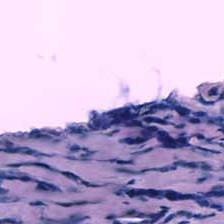

Pearson (patch-wise)     0.534598
Spearman (patch-wise)    0.451987
MAE                      2.166272
MSE                      8.886388
MAPE (%)                47.907252


In [12]:
metrics = run_demo()
# To download Flash weights and extract features from the original patches:
# metrics = run_demo(source="images", data_dir=ROOT / "data/hist2st")


Pearson and Spearman are across the 845 genes of one patch. This is a patch result, not the fold-3 average. The saved embeddings are for the full 256-spot spatial window; new patches need their matching window and coordinates.